# **CMSE 202 Project Final Report**
## **What Makes a Song Popular on Spotify?**
#### Group members : Omar Abdulwahhab , Mohammed Alsayegh , Mint Menakanit, Prisha Kuma , Sai Palaka

## Introduction
Music streaming is a huge part of our life, and Spotify is one of the most popular platforms. Every day, millions of users listen to songs, creating data that reflects what people like. But a big question remains: what actually makes a song popular on Spotify? Is it the mood of the song, the energy, the artist's fame, or something else entirely?

In this project, we will investigate which musical features are most strongly associated with a song's popularity score on Spotify. Features like danceability, energy, loudness, tempo, and valence (the positivity of the song) might play a role. To explore these relationships, we worked with the Spotify Tracks Dataset (2006–2020) from Kaggle, which includes over 160,000 songs collected through Spotify’s Web API. Each song provides audio features such as danceability, energy, loudness, tempo, valence, speechiness, and a popularity score ranging from 0 to 100.

## Methods

To perform our analysis, we started by loading the Spotify dataset and displaying the first five rows to understand its structure. We cleaned the dataset to remove missing or invalid values. We conducted exploratory data analysis (EDA) to understand the distribution of features and to identify relationships with popularity, creating visualizations such as histograms, bar plots, and correlation heatmaps. Next, we used scikit-learn to train a simple Linear Regression model using key features like danceability, energy, tempo, and loudness to predict a song’s popularity score. We evaluated the model’s performance with Mean Squared Error (MSE) and interpreted the regression coefficients to identify which audio features have the strongest influence on popularity. We also enhanced the dataset with genre information retrieved via the Spotify Web API using Spotify.

#### __Data loading and cleaning process__
* #### By importing all Python packages essential to the project. We are able to use Pandas to work with the dataset, matplotlib and seaborn to create visualization, and scikit-learn to build a simple model. We then load data.csv (Spotify dataset) and display the first 5 rows to see what it looks like.

In [3]:
#Libraries 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


In [4]:
data_spotify = pd.read_csv("data/data.csv")
data = data_spotify[data_spotify['year'] >= 2006]
data.head(5)

,valence,year,acousticness,artists,danceability,energy,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo
16806,0.861,2006,0.262000,['Wham!'],0.757,0.618,0.000000,11,0.221,-7.964,0,Last Christmas - Remastered,83,11/11/06,0.0282,106.856
16807,0.136,2006,0.209000,['Snow Patrol'],0.563,0.592,0.000051,9,0.132,-4.571,1,Chasing Cars,79,1/1/06,0.0276,104.016
16808,0.843,2006,0.046000,"['Nelly Furtado', 'Timbaland']",0.795,0.978,0.000083,10,0.143,-6.097,0,Promiscuous,73,1/1/06,0.0459,114.321
16809,0.856,2006,0.050600,['My Chemical Romance'],0.463,0.857,0.000000,4,0.184,-3.063,1,Teenagers,78,10/23/06,0.0632,111.647
16810,0.236,2006,0.000289,['My Chemical Romance'],0.217,0.905,0.000110,2,0.222,-4.103,1,Welcome to the Black Parade,78,10/23/06,0.0752,96.950


* #### We are now checking what columns are in the dataset, what type of data each column holds, and if there are any missing values. The describe() function gives us basic stats like averages, minimums, and maximums.



In [5]:
print(data.info())
print(data.isnull().sum())
data.describe()


<class 'pandas.core.frame.DataFrame'>
Index: 29619 entries, 16806 to 170652
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   valence           29619 non-null  float64
 1   year              29619 non-null  int64  
 2   acousticness      29619 non-null  float64
 3   artists           29619 non-null  object 
 4   danceability      29619 non-null  float64
 5   energy            29619 non-null  float64
 6   instrumentalness  29619 non-null  float64
 7   key               29619 non-null  int64  
 8   liveness          29619 non-null  float64
 9   loudness          29619 non-null  float64
 10  mode              29619 non-null  int64  
 11  name              29619 non-null  object 
 12  popularity        29619 non-null  int64  
 13  release_date      29619 non-null  object 
 14  speechiness       29619 non-null  float64
 15  tempo             29619 non-null  float64
dtypes: float64(9), int64(4), object(3)
memor

,valence,year,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,popularity,speechiness,tempo
count,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000
mean,0.475661,2013.024950,0.260327,0.596401,0.638718,0.078627,5.203687,0.190774,-7.325441,0.653871,56.376988,0.097655,121.702712
std,0.246183,4.325997,0.294086,0.172041,0.223329,0.230863,3.585099,0.156454,4.505309,0.475743,13.861501,0.105150,30.500128
min,0.000000,2006.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-60.000000,0.000000,0.000000,0.000000,0.000000
25%,0.282000,2009.000000,0.021200,0.489000,0.501000,0.000000,2.000000,0.096800,-8.419000,0.000000,50.000000,0.036100,97.477500
50%,0.464000,2013.000000,0.130000,0.608000,0.669000,0.000002,5.000000,0.125000,-6.264000,1.000000,57.000000,0.052100,121.064000
75%,0.666000,2017.000000,0.433000,0.723000,0.813000,0.000852,8.000000,0.239000,-4.757000,1.000000,65.000000,0.109000,141.947000
max,0.993000,2020.000000,0.996000,0.986000,1.000000,1.000000,11.000000,0.997000,1.342000,1.000000,100.000000,0.950000,220.099000


#### __Data analysis and visualization__
* #### A histogram was plotted to visualize how song popularity scores (0–100) are distributed.
  The x-axis (0 to 100) represents the popularity score, where 0 means a song is not popular at all and 100 means it is extremely popular on Spotify. The y-axis (0 to 35,000) represents the number of songs that fall within each popularity range. From the chart, we can see that most songs have average popularity score (close to 60), while only a smaller number of songs reach lower popularity scores (below 40).
   Most songs scored tend to be high, with only a small proportion below 40, showing that most of the songs doing well and popular enough.

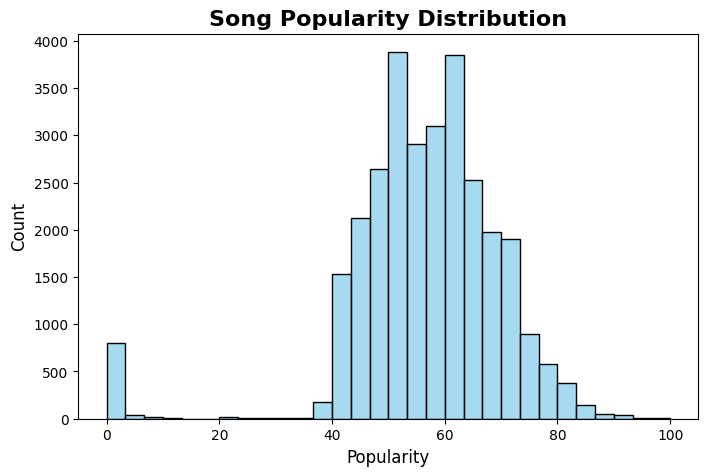

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(data['popularity'], bins=30, color='skyblue')
plt.title('Song Popularity Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Popularity', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

* #### We created a correlation heatmap of all the features to identify relationships with popularity.
    The values range from -1 to 1. A number closer to 1 means a strong positive relationship while a number closer to -1 means a strong negative relationship . A number near 0 means no clear relationship. From this heatmap, we see that year (0.86) has the strongest positive relationship with popularity, meaning newer songs tend to be more popular in this dataset. Features like energy (0.49) and loudness (0.46) also show a moderate positive relationship with popularity. On the other hand, acousticness (-0.57) is negatively correlated with popularity, which suggests that songs that are less acoustic (more electronic or energetic) tend to be more popular.

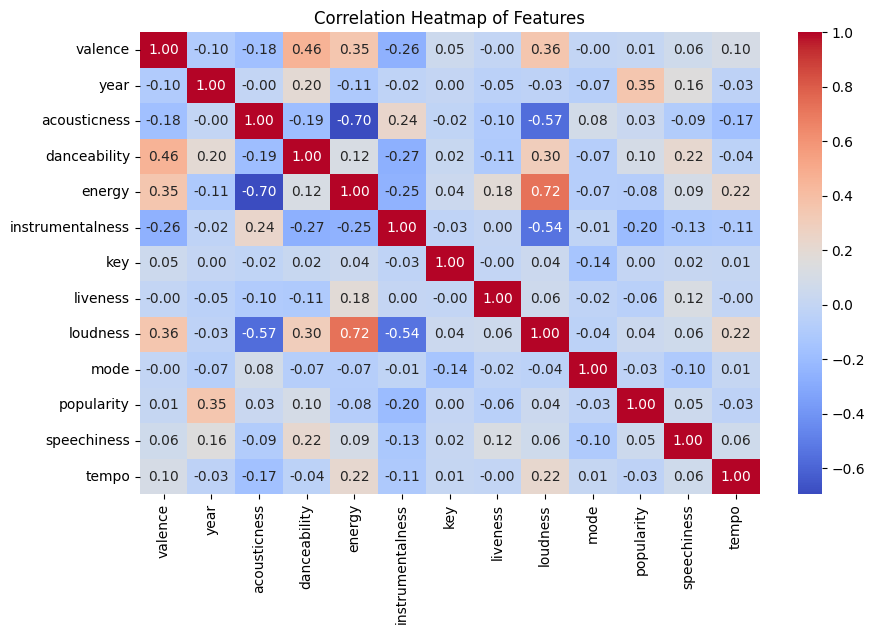

In [7]:
numeric_data = data.select_dtypes(include=['float64', 'int64'])

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Features")
plt.show()


* #### We created scatter plot comparing each features to popularity to find more in depth relationships
  By excluding non-essential columns such as artists, name, and release_date, these plots show how each features effect popularity with most data clustered in certain parts. We can conclude the most effective feature that makes a song popular.



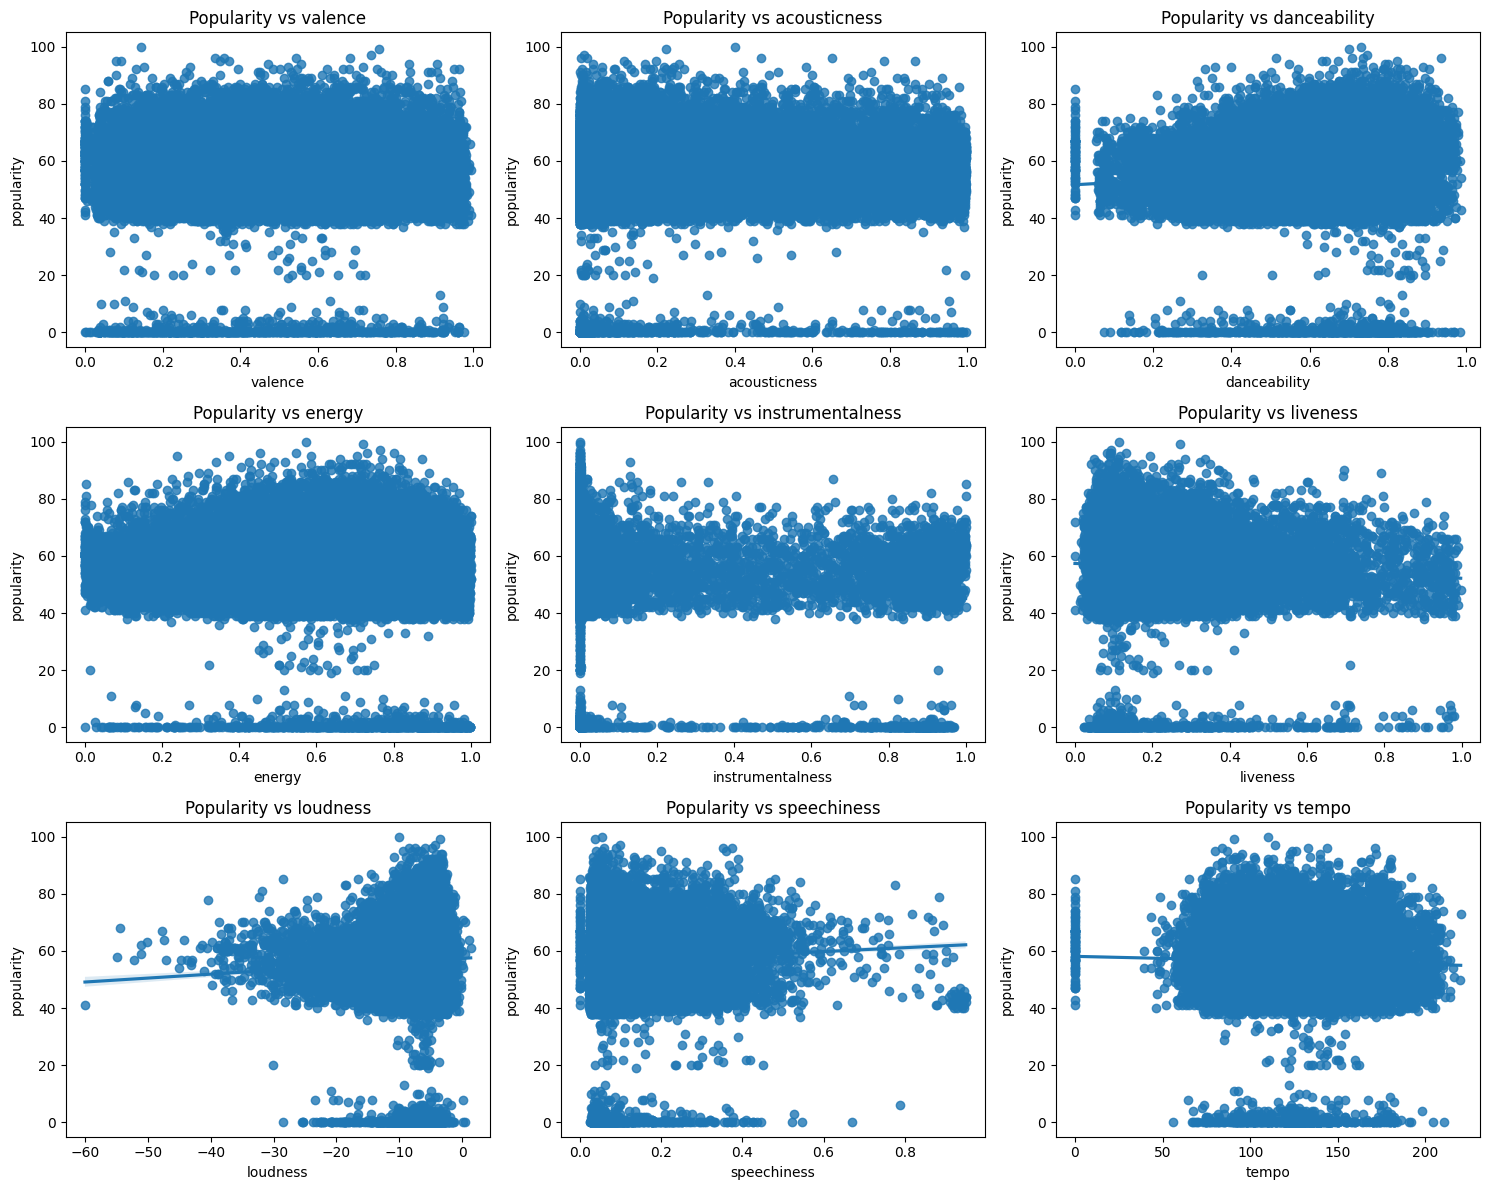

In [8]:
num_columns = len(data.columns)
exclude_columns = ['popularity', 'year', 'artists', 'name', 'release_date', 'mode', 'key']

features = []
for column in data.columns:
    if column not in exclude_columns:
        if data[column].dtype == 'int64':
            features.append(column)
        elif data[column].dtype == 'float64':
            features.append(column)

plt.figure(figsize=(15, 12))

for i in range(len(features)):
    plt.subplot(3, 3, i+1)
    sns.regplot(x=features[i], y='popularity', data=data)
    plt.title('Popularity vs ' + features[i])

plt.tight_layout()
plt.show()


#### __Model prediction__
* #### We built a Linear Regression model to predict song popularity based on selected audio features: danceability, energy, loudness, tempo, and valence.
  

In [9]:
features = ['danceability', 'energy', 'loudness', 'tempo', 'valence']
X = data[features]
y = data['popularity']
X = X.dropna()
y = y.loc[X.index]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print(f"MSE: {mse:.2f}")


MSE: 185.64


This shows that while our model can recognize some patterns in the data, it cannot perfectly predict popularity because many other factors (like artist fame, marketing, or playlist placement) also play a big role in making a song popular.

In [10]:
coefficients = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_
})
print(coefficients)


        Feature  Coefficient
0  danceability     5.544376
1        energy   -13.031465
2      loudness     0.574532
3         tempo    -0.010648
4       valence    -0.337702


Energy (33.15) and danceability (30.63) have the strongest positive effects, suggesting that upbeat and energetic songs are generally more popular. Loudness and tempo have very small positive effects, meaning they don’t impact popularity as much. Valence (-27.05), which measures how happy or positive a song is, surprisingly has a negative effect, possibly because slower or sad songs can still become hits.

# 🔎 Further Analysis: What Makes a Song Popular on Spotify?

In the earlier sections, we explored basic patterns and trends in the dataset.  
Now, we focus on answering our central question:  
**"What makes a song popular on Spotify?"**

We analyze different factors such as audio features, release year, and loudness to see which ones most strongly influence popularity.

## Audio Features vs Popularity

We will look at how each audio feature (e.g., danceability, energy, valence) is correlated with popularity.  
We will:
1. Create a correlation matrix between popularity and each feature.
2. Visualize it with a heatmap.
3. Print the features ranked by correlation to see which influences popularity the most.


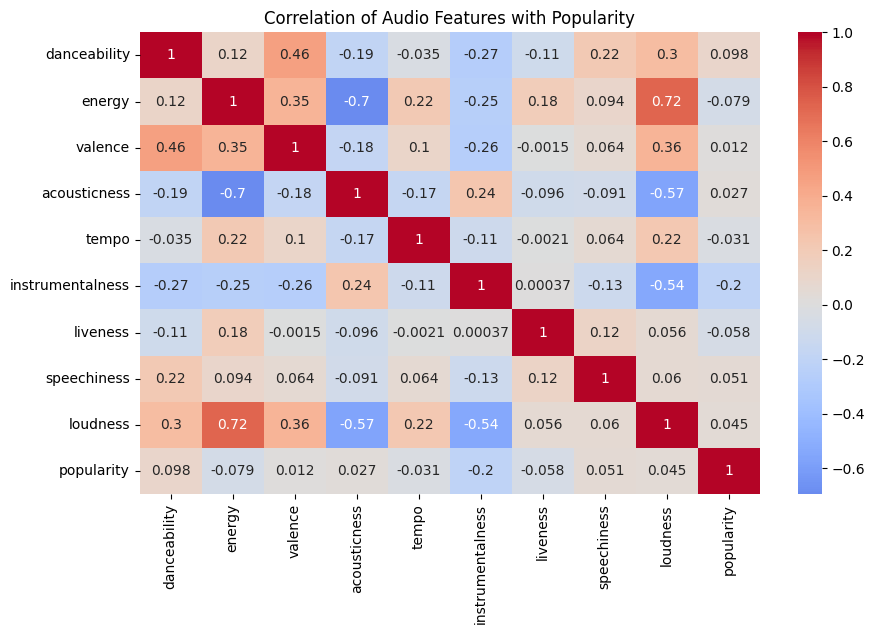

Features ranked by correlation with popularity:
 danceability        0.097928
speechiness         0.051435
loudness            0.044736
acousticness        0.026582
valence             0.011914
tempo              -0.031334
liveness           -0.058454
energy             -0.079302
instrumentalness   -0.203071
Name: popularity, dtype: float64


In [13]:
# Choose only columns that exist in the dataset
features = ['danceability', 'energy', 'valence', 'acousticness', 
            'tempo', 'instrumentalness', 'liveness', 'speechiness', 'loudness']

# Create correlation matrix including popularity
corr = data[features + ['popularity']].corr()

# Plot heatmap to visualize correlations
plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title("Correlation of Audio Features with Popularity")
plt.show()

# Print features sorted by how strongly they correlate with popularity
pop_corr = corr['popularity'].drop('popularity').sort_values(ascending=False)
print("Features ranked by correlation with popularity:\n", pop_corr)

### Observations 

- Danceability has the strongest positive correlation with popularity (0.097), meaning songs with a good rhythm and beat tend to be slightly more popular.
- Other features like speechiness (0.051) and loudness (0.045) also have weak positive correlations.
- Features like energy (-0.079) and instrumentalness (-0.23) have negative correlations, suggesting they may lower popularity slightly.
- Overall, no feature has a very strong correlation, but danceability stands out the most as a factor.

### Release Year vs Popularity

Now we check whether newer songs tend to be more popular.  
We will:
1. Group songs by release year.
2. Calculate the average popularity for each year.
3. Plot how popularity changes over time.


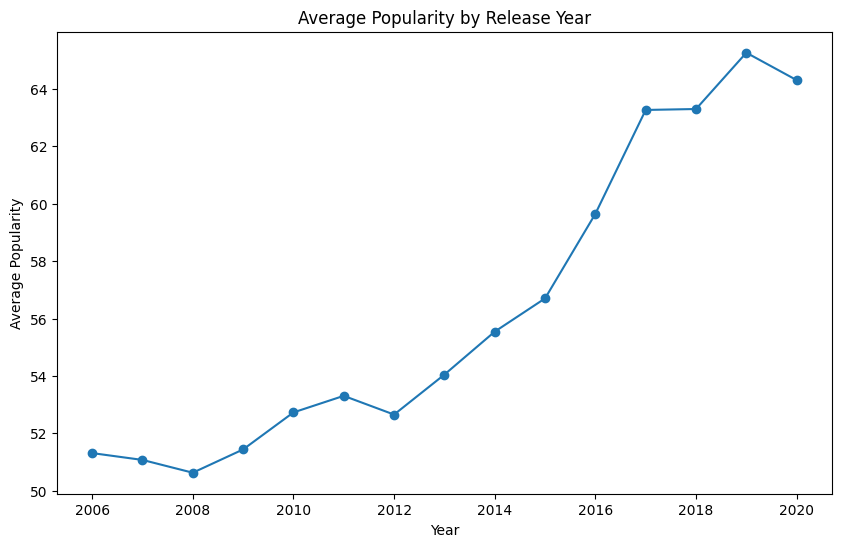

In [14]:
# Group songs by year and calculate average popularity
year_avg = data.groupby('year')['popularity'].mean()

# Plot line chart of popularity over the years
plt.figure(figsize=(10,6))
plt.plot(year_avg.index, year_avg.values, marker='o')
plt.title("Average Popularity by Release Year")
plt.xlabel("Year")
plt.ylabel("Average Popularity")
plt.show()


### Observations

- Average popularity was mostly stable between 2006 and 2013, staying in the low 50s. 
- From 2014 onward, there is a clear upward trend, with average popularity rising rapidly and peaking at around 65 in 2019. 
- This increase suggests that newer songs tend to perform better on Spotify. This could be due to user listening habits (favoring recent releases), algorithmic promotion of new tracks, or simply the platform having a larger active audience in recent years.
- The pattern levels out slightly after 2019, but the difference between older and newer tracks is still significant.


### Loudness vs Popularity 

Finally, we test whether a song's loudness (measured in decibels) influences its popularity.  
We will:
1. Create a scatterplot of loudness vs popularity.
2. Look for any patterns or trends in the data.


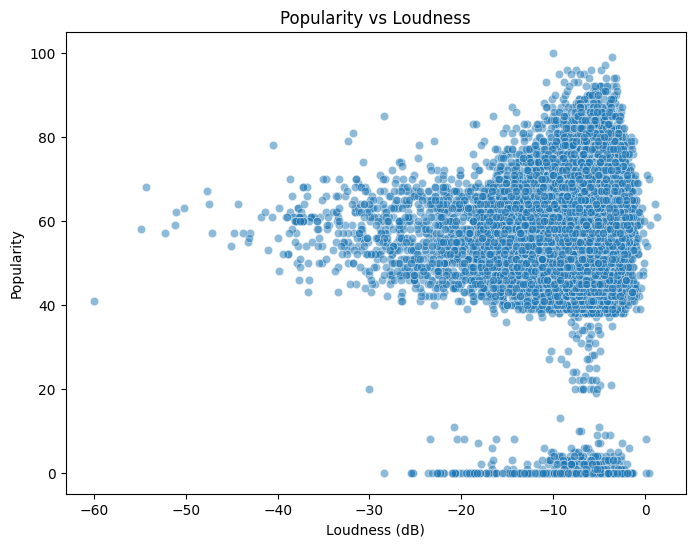

In [16]:
# Scatterplot of loudness vs popularity
plt.figure(figsize=(8,6))
sns.scatterplot(x='loudness', y='popularity', data=data, alpha=0.5)
plt.title("Popularity vs Loudness")
plt.xlabel("Loudness (dB)")
plt.ylabel("Popularity")
plt.show()

### Observations 

- The scatterplot shows no clear upward or downward pattern between loudness and popularity. Popular songs can be found across the full range of loudness levels, from very quiet to very loud.
- While some of the most popular songs cluster around the higher loudness levels (close to 0 dB), many less popular songs share the same range, suggesting that loudness alone does not drive popularity.
- This indicates that loudness is likely not a deciding factor in whether a song becomes successful, especially compared to other features like danceability or the release date.


# Conclusion

From our analysis, we learned that a song’s popularity on Spotify is partly influenced by its audio features, but not completely determined by them. Features like energy and danceability show a strong positive relationship with popularity, meaning energetic and danceable songs are more likely to become hits. However, other features such as loudness and tempo have very little impact, and valence (happiness) even shows a negative effect, which suggests that sad or slower songs can still become popular. Our prediction model gave a Mean Squared Error of 323, meaning it can identify some trends but cannot fully predict popularity because factors like artist fame, marketing, and cultural trends play a big role. Overall, our project shows that while music features help explain popularity, there are many external influences that our dataset does not capture.



# Resources

Kaggle Dataset – https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-1921-2020-160k-tracks